# Case Study 1: Exploring Customer Data for a Retail Company
**Dataset:** `customer_data.csv` (100 customers)

## Step 1: Data Collection

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Load the real dataset
df = pd.read_csv('customer_data.csv')
df

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29
...,...,...,...,...,...,...,...
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17


In [8]:
# shape (rows & columns)
print(f"Shape: {df.shape}")

Shape: (100, 7)


In [9]:
# Display first 5 records
df.head() 

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29


In [10]:
#Check Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    str    
 3   Location          100 non-null    str    
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 5.6 KB


## Step 2: Data Preprocessing

### Data Cleaning:-

In [11]:
# Check Missing Values
df.isnull().sum()

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64

In [12]:
# Step 1: Convert Date Column
# Convert the 'LastPurchaseDate' column from text (string)
# into a proper DateTime format.
df['LastPurchaseDate'] = pd.to_datetime(df['LastPurchaseDate'])     
df['LastPurchaseDate']

0    2023-01-01
1    2023-01-08
2    2023-01-15
3    2023-01-22
4    2023-01-29
        ...    
95   2024-10-27
96   2024-11-03
97   2024-11-10
98   2024-11-17
99   2024-11-24
Name: LastPurchaseDate, Length: 100, dtype: datetime64[us]

In [13]:
# Step 2: Clean Gender Column
# Remove extra spaces from the Gender column
# and convert the text into Title Case.

df['Gender'] = df['Gender'].str.strip().str.title()
df['Gender']

# .str -> Perform string operations on every value in the column.
# strip() -> Removes spaces at the beginning and end.
# title() -> Converts the first letter of each word to uppercase.

0     Female
1       Male
2       Male
3     Female
4       Male
       ...  
95    Female
96    Female
97      Male
98    Female
99    Female
Name: Gender, Length: 100, dtype: str

In [14]:
# Step 3: Clean Location Column
df['Location'] = df['Location'].str.strip().str.title()
df['Location']

0         Houston
1         Phoenix
2         Phoenix
3         Chicago
4     Los Angeles
         ...     
95        Phoenix
96        Houston
97        Houston
98        Houston
99        Chicago
Name: Location, Length: 100, dtype: str

### Data Validation:-

In [15]:
# Step 4: Check Purchase Count
# Check that every customer has purchased
# at least one item.

# assert -> Stop the program if the condition is False.
assert (df['TotalPurchases'] > 0).all()   # Checks every row.

# .all() -> Means are all values True?
# If yes → continue.
# If no → stop with an error.

In [16]:
# Step 5: Check Spend
assert (df['TotalAmountSpent'] > 0).all()

# Checks that every customer spent more than 0.

In [17]:
# Step 6: Check Age
assert df['Age'].between(0,100).all()  # Found invalid age values

# .between() -> Checks whether values lie within a range.

In [18]:
invalid_age = df[(df['Age'] >= 0) & (df['Age'] <= 100)]
invalid_age

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29
...,...,...,...,...,...,...,...
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17


### Feature engineering:- 

In [19]:
# Step 7: Create Average Order Value
# Calculate the average amount spent
# in each purchase.

# .round(2) -> Rounds the result to 2 decimal places.
# spend per transaction
df['AvgOrderValue'] = (df['TotalAmountSpent'] / df['TotalPurchases']).round(2)
df['AvgOrderValue']

0      24.80
1     100.05
2     216.31
3      86.10
4      74.84
       ...  
95    308.44
96      2.37
97    709.50
98    147.51
99    174.70
Name: AvgOrderValue, Length: 100, dtype: float64

In [20]:
# Step 8: Create Age Groups

# Divide customers into age groups.
# pd.cut() -> Splits continuous numerical values into categories (bins).
# bins -> Defines the range of each category.
# labels -> Assigns a readable name to each bin.
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17,25,35,45,55,70],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-70'
    ]
)

df['AgeGroup']

0     56-70
1     26-35
2     56-70
3     56-70
4     36-45
      ...  
95    36-45
96    18-25
97    56-70
98    56-70
99    26-35
Name: AgeGroup, Length: 100, dtype: category
Categories (5, str): ['18-25' < '26-35' < '36-45' < '46-55' < '56-70']

In [21]:
# Step 9: Print Message
print("Data cleaned. No missing values, no invalid records.")

Data cleaned. No missing values, no invalid records.


In [22]:
# Step 10: Show Data
df.head()  

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AvgOrderValue,AgeGroup
0,1,68,Female,Houston,24,595.11,2023-01-01,24.80,56-70
1,2,35,Male,Phoenix,29,2901.57,2023-01-08,100.05,26-35
2,3,60,Male,Phoenix,19,4109.95,2023-01-15,216.31,56-70
3,4,63,Female,Chicago,27,2324.75,2023-01-22,86.10,56-70
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29,74.84,36-45


## Step 3: Data Analysis

> Key metrics to explore include:
> - Average Purchase Value by age and gender.
> - Total Purchase Amount by location.
> - Churn Rate and customer loyalty based on purchase frequency.

### 3a. Customer Demographics
> This is a Visualization (EDA) code block. The goal is to create 3 graphs in one figure:
> - Age Distribution (Histogram)
> - Gender Split (Pie Chart)
> - Customers by Location (Horizontal Bar Chart)

> - **Histogram** → Understand the distribution of a numerical feature (Age).
> - **Pie Chart** → Visualize the proportion of categories (Gender).
> - **Horizontal Bar Chart** → Compare category counts (Location), especially when category names are long.

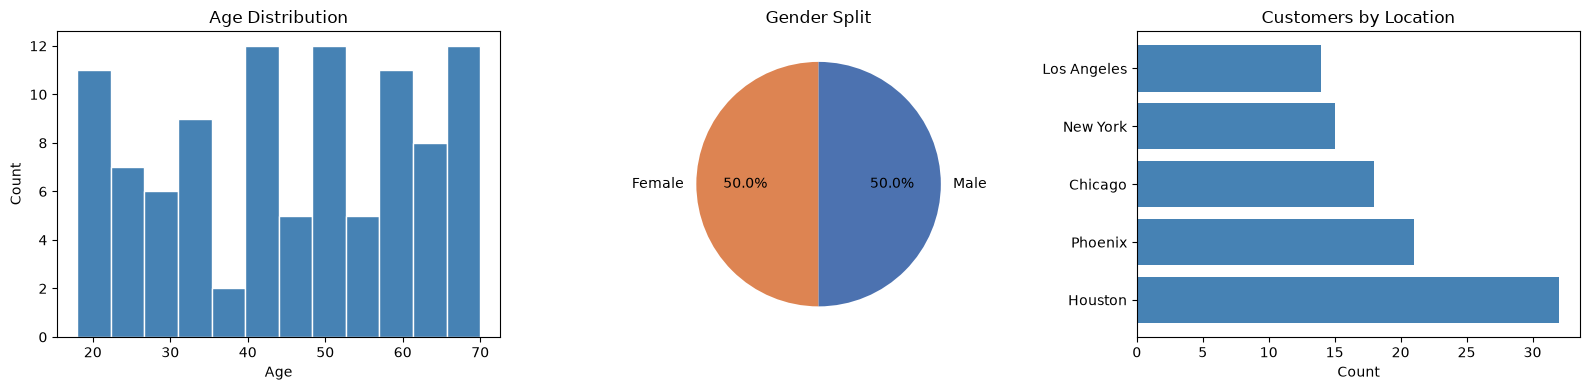

Median age: 46 | Gender split: {'Female': 50, 'Male': 50}


In [23]:
# Create one figure with 3 graphs in a single row
# subplots() -> It creates multiple graphs together.
# axes -> Axes means the individual graph area.
# figsize=(16, 4) -> width(16 inches) & height(4 inches)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# -------------------------------
# Graph 1 : Age Distribution
# -------------------------------

# Draw a histogram using the Age column
# histogram shows how data is distributed.
axes[0].hist(
    df['Age'],           # Data to plot
    bins=12,             # Divide ages into 12 groups
    color='steelblue',   # Bar color
    edgecolor='white'    # White border around bars
)

# set_title() -> Adds title above graph
axes[0].set_title('Age Distribution')

# set_xlabel() -> Adds Label below X-axis
axes[0].set_xlabel('Age')

# set_ylabel() -> Adds Label below Y-axis
# Count = Number of customers
axes[0].set_ylabel('Count')


# -------------------------------
# Graph 2 : Gender Split
# -------------------------------

# value_counts() -> Count every unique value.
# Count Male and Female customers
g = df['Gender'].value_counts()

# Draw Pie Chart
axes[1].pie(
    g,                       # Values
    labels=g.index,          # Labels (male, female)
    autopct='%1.1f%%',       # Show percentage
    colors=['#DD8452','#4C72B0'],
    startangle=90            # Rotates charts
)

# Give title
axes[1].set_title('Gender Split')


# -------------------------------
# Graph 3 : Customers by Location
# -------------------------------

# Count customers in every city
loc = df['Location'].value_counts()

# Draw Horizontal Bar Chart
# barh() -> Horizontal Bar Chart.
axes[2].barh(
    loc.index,      # City names
    loc.values,     # Customer count
    color='steelblue'
)

# Give title
axes[2].set_title('Customers by Location')

# X-axis label
axes[2].set_xlabel('Count')


# -------------------------------
# Final Settings
# -------------------------------


# tight_layout() -> automatically adjusts spacing so 
# graphs don't overlap.
plt.tight_layout()

# savefig() -> Save the graphs as as image
# bbox_inches='tight'-> It removes extra white space 
# around the figure.
plt.savefig(
    'demographics.png',
    dpi=120,               # dpi -> image quality
    bbox_inches='tight' 
)

# Display all graphs
plt.show()

# Print summary
# median() -> Finds the middle age after sorting.
# :.0f -> Formats the number with 0 decimal places.
# g.to_dict() -> converts the counts into a dictionary.
print(
    f"Median age: {df['Age'].median():.0f} | "
    f"Gender split: {g.to_dict()}"
)

### 3b. Average Purchase Value by Age & Gender

> This code is performing **GroupBy + Pivot Table + Visualization**, which is a very common task in EDA (Exploratory Data Analysis).

> Goal of this code:
> - Find the Average Order Value for each Age Group and Gender, then visualize the result **using a bar chart**.

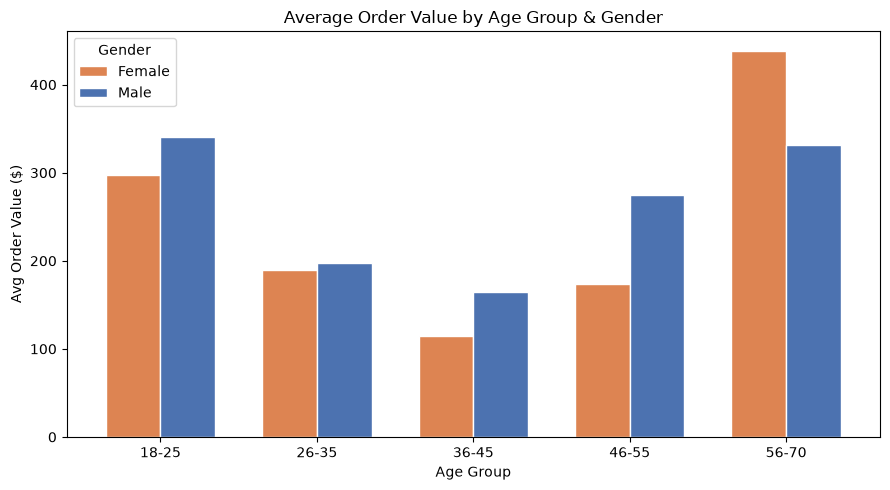

Gender    Female    Male
AgeGroup                
18-25     297.55  340.11
26-35     189.63  197.73
36-45     114.91  164.85
46-55     173.98  274.69
56-70     438.60  331.64


In [24]:
# Group the data by Age Group and Gender & making its separate folders
# Then calculate the Average Order Value for each group
# Finally, convert the result into a table (pivot table)

# Instead of using the whole dataset, use only -> AvgOrderValue
# unstack() -> This converts the grouped result into 
# a table (pivot-table-like format).
avg_purchase = (
    df.groupby(['AgeGroup', 'Gender'])['AvgOrderValue']
      .mean()
      .unstack()
)

# Draw a bar chart from the pivot table
avg_purchase.plot(
    kind='bar',           # Draw a vertical bars
    figsize=(9,5),        # width = 9 & height = 5  
    color=['#DD8452','#4C72B0'], # [Female , Male]
    edgecolor='white',  # Adds white borders around the bars
    width=0.7           # bar thickness
)

# Give the chart a title
plt.title('Average Order Value by Age Group & Gender')

# X-axis Label
plt.xlabel('Age Group')

# Y-axis Label
plt.ylabel('Avg Order Value ($)')

# Keep X-axis labels horizontal
plt.xticks(rotation=0)   # don't rotate Labels

# tight_layout() -> automatically adjusts spacing so 
# labels and titles don't overlap.
plt.tight_layout()

# Save the graph as an image
# bbox_inches='tight' -> Removes extra white space 
# around the image.
plt.savefig('avg_purchase.png', 
            dpi=120, 
            bbox_inches='tight')

# Display the graph
plt.show()

# Display the pivot table with values rounded to 2 decimal places
print(avg_purchase.round(2))

#### Q: Why use groupby().mean().unstack() instead of pivot_table()?

> Answer:
> - **groupby()** is more flexible and is often used when you need multiple operations or custom logic.
> - **pivot_table()** is more concise and beginner-friendly when your goal is simply to summarize data in a table format.

> For this example, both approaches produce the same result, but pivot_table() is usually easier to read.

### 3c. Total Purchase Amount by Location

> This code is performing Revenue Analysis by Location:-
> - Which city generated the highest revenue?
> - How much revenue each city generated?
> - Show the result in a Bar Chart.

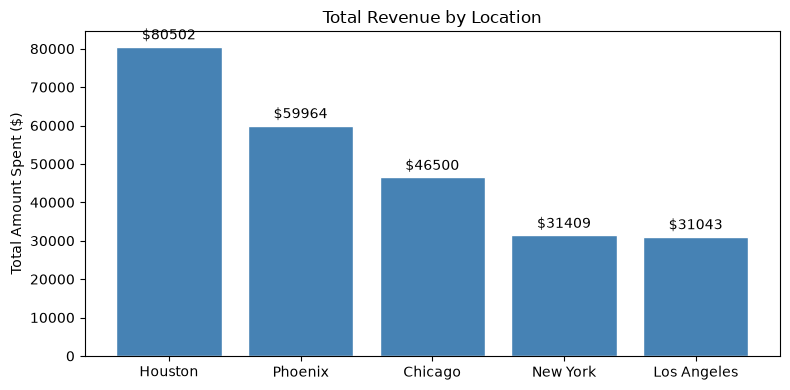

Top revenue city: Houston ($80,502)


In [25]:
# Group the data by Location (City)
# Add (sum) all the money spent by customers in each city
# Arrange cities from highest revenue to lowest revenue

# Group all customers based on Location (City).
loc_revenue = (
    df.groupby('Location')['TotalAmountSpent']
      .sum()
      .sort_values(ascending=False)
)

# Create a figure (canvas) and one graph (axes)
# fig -> Entire page(Figure)
# ax -> Graph area(Axes)
fig, ax = plt.subplots(figsize=(8,4))

# Draw a Vertical bar chart
bars = ax.bar(
    loc_revenue.index,      # City names (X-axis)
    loc_revenue.values,     # Revenue values (Y-axis)
    color='steelblue',
    edgecolor='white'
)

# Display the revenue value on top of each bar
# padding = 3 -> Adds a small gap between the bar 
# and its label so the text doesn't touch the bar.
ax.bar_label(
    bars,
    fmt='$%.0f',
    padding=3
)

# Add a title above the chart.
ax.set_title('Total Revenue by Location')

# Label the Y-axis
ax.set_ylabel('Total Amount Spent ($)')

# Automatically adjusts spacing so titles, 
# labels, and the graph don't overlap.
plt.tight_layout()

# Saves the graph as an image file.
# bbox_inches='tight' -> Removes extra white space 
# around the saved image.
plt.savefig(
    'revenue_by_location.png',
    dpi=120,
    bbox_inches='tight'
)

# Display the graph
plt.show()

# loc_revenue.idmax() -> Find the index (city name) 
# with the highest revenue.

# loc_revenue.max() -> Find the highest revenue value.
# :, -> Adds commas to large numbers
# .of -> Removes all decimal places
print(
    "Top revenue city:",
    loc_revenue.idxmax(),
    f"(${loc_revenue.max():,.0f})"
)

### 3d. Churn Risk & Customer Loyalty (based on Purchase Frequency)

> **Churn Risk**-> It helps identify customers who are likely to stop purchasing.

In [26]:
# Step 1: Decide who is at-risk
# Customers with very few purchases are considered more likely to leave.
# We use the bottom 25% of customers based on TotalPurchases.
# quantile(0.25) -> Finds the 25th percentile (Bottom 25%).

threshold = df['TotalPurchases'].quantile(0.25)

In [27]:
# Step 2: Create the ChurnRisk Column
# If a customer's purchases are less than or equal to the threshold,
# mark them as "At-Risk".
# Otherwise, mark them as "Loyal".

# np.where() -> Think of it as an IF-ELSE statement 
# for an entire-column.
df['ChurnRisk'] = np.where(
    df['TotalPurchases'] <= threshold,
    'At-Risk',
    'Loyal'
)

In [28]:
# Step 3: Count Loyal and At-Risk customers
# in each Age Group


# .size() -> Count the number of rows in each group
# .unstack(fill_value=0) -> convert the grouped result 
# into a table
# fill_value=0 -> If a group doesn't exist, fill it 
# with 0 instead of NaN.
churn_by_age = (
    df.groupby(['AgeGroup', 'ChurnRisk'])
      .size()
      .unstack(fill_value=0)
)

In [29]:
# Step 4: Convert customer counts into percentages.

# sum(axis=1) -> add each row
# .div(..., axis=0) -> divides every row by its total
churn_pct = (
    churn_by_age.div(
        churn_by_age.sum(axis=1),
        axis=0
    ) * 100
)

<Axes: xlabel='AgeGroup'>

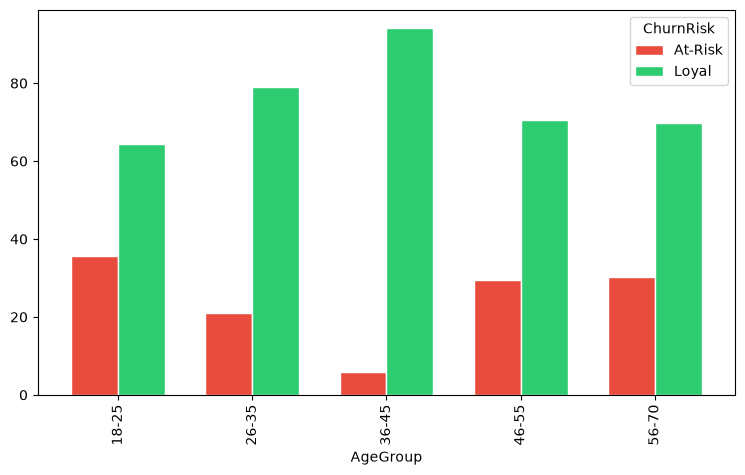

In [30]:
# Step 5: Create a bar chart
churn_pct.plot(
    kind='bar',      # bar chart
    figsize=(9,5),   # width = 9 & height = 5
    color=['#e74c3c', '#2ecc71'],
    edgecolor='white',
    width=0.7
)

Text(0.5, 1.0, 'Churn Risk % by Age Group (At-Risk = bottom 25% by purchase frequency)')

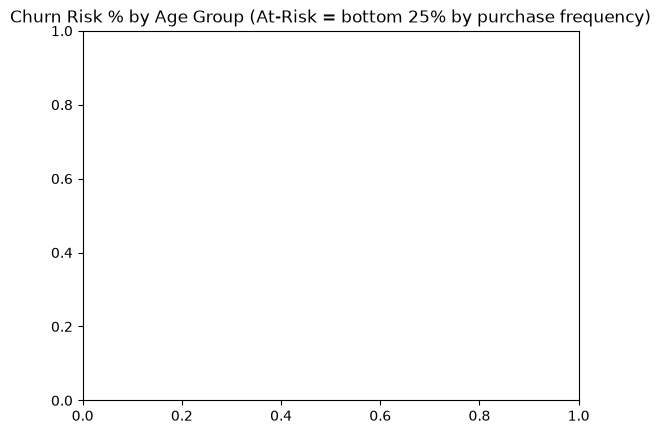

In [31]:
# Step 6: Adds a title to the graph
plt.title('Churn Risk % by Age Group (At-Risk = bottom 25% by purchase frequency)')

Text(0.5, 0, 'Age Group')

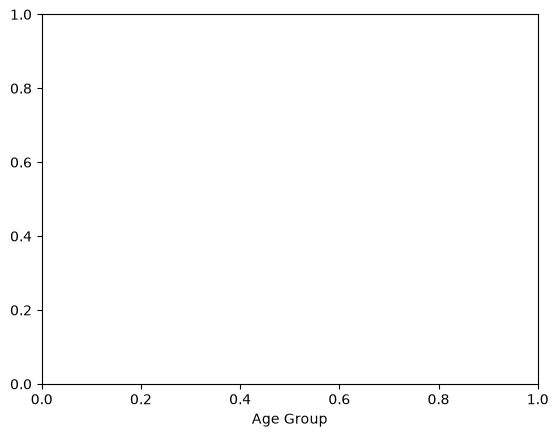

In [32]:
# Step 7: Adds the X-axis label
plt.xlabel('Age Group')

Text(0, 0.5, 'Percentage (%)')

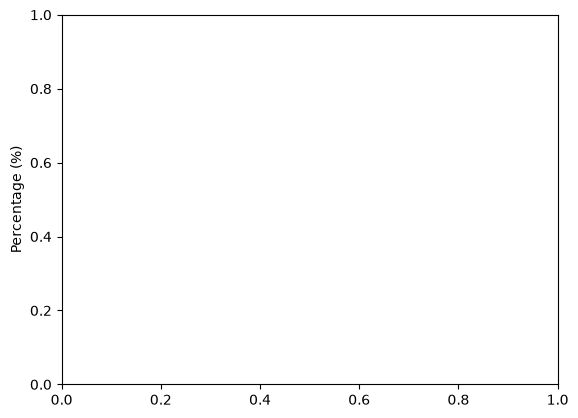

In [33]:
# Step 8: Adds the Y-axis label
plt.ylabel('Percentage (%)')

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

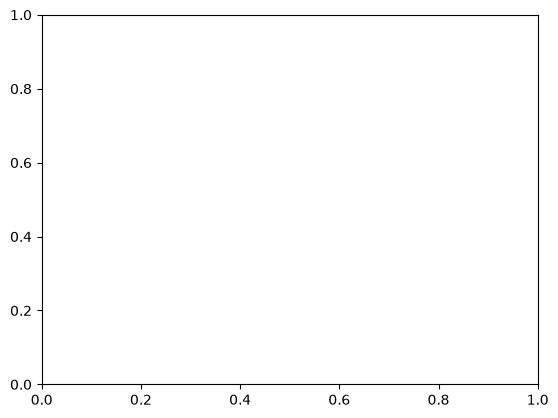

In [34]:
# Step 9: Keep X-axis(age group) labels horizontal
plt.xticks(rotation=0)

In [35]:
# Step 10: Automatically adjusts spacing so 
# labels are not cut off.
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [36]:
# Step 11: Saves the graph as an image.
# bbox_inches='tight' → Removes extra empty space around the figure
plt.savefig(
    'churn_risk.png',
    dpi=120,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [37]:
# Step 12: Displays the graph
plt.show()

In [38]:
# Step 13: Calculate Overall Churn Risk
# Calculate the percentage of customers
# who are marked as At-Risk.

overall_churn = (
    df['ChurnRisk'] == 'At-Risk'
).mean() * 100

overall_churn

np.float64(25.0)

In [39]:
# Step 14: Print Result
# {overall_churn:.1f} → Shows 1 decimal place (e.g., 25.3%).
# {threshold:.0f} → Shows the threshold as a whole number (e.g., 12 orders).

print(f"Overall at-risk rate: {overall_churn:.1f}% | Purchase-count threshold: {threshold:.0f} orders")

Overall at-risk rate: 25.0% | Purchase-count threshold: 10 orders


### 3e. Most Valuable Customers (Top 10% by Spend)

In [40]:
# Find the customers who have spent the most money.
# These customers are valuable because we can give 
# them special offers to keep them buying from us.

# Calculate how many customers belong to the top 10%.
# Example: If there are 100 customers, top_n = 10.
# max(1, ...) makes sure we always select at least 1 customer.

# len(df) -> Returns the total number of customers (rows).
# max(1,...) -> Ensures that at least 1 customer is 
# selected, even if the dataset is very small.
top_n = max(1, int(len(df) * 0.10)) # Finds 10% of the customers.

# Select the top 'top_n' customers based on TotalAmountSpent.
# nlargest() sorts the data from highest to lowest spending
# and returns only the top customers.
top_customers = df.nlargest(top_n, 'TotalAmountSpent')[

    # Display only these useful columns.
    [
        'CustomerID',        # Customer ID
        'Age',               # Customer's age
        'Gender',            # Male/Female
        'Location',          # Customer's city/location
        'TotalPurchases',    # Number of purchases made
        'TotalAmountSpent',  # Total money spent
        'AvgOrderValue'      # Average amount spent per order
    ]
]

# Print a heading before displaying the result.
# Example output: "Top 10 customers by total spend (top 10%):"
print(f"Top {top_n} customers by total spend (top 10%):")

# Display the DataFrame containing the highest-spending customers.
top_customers

Top 10 customers by total spend (top 10%):


,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,AvgOrderValue
97,98,60,Male,Houston,7,4966.48,709.50
38,39,18,Female,Phoenix,5,4947.37,989.47
44,45,69,Female,Houston,11,4880.54,443.69
42,43,66,Female,Houston,15,4835.52,322.37
40,41,20,Female,Phoenix,12,4785.73,398.81
78,79,43,Male,Chicago,30,4766.31,158.88
63,64,57,Male,Houston,10,4532.50,453.25
33,34,43,Female,Chicago,28,4467.34,159.55
87,88,49,Female,Houston,9,4380.05,486.67
23,24,31,Male,Los Angeles,8,4302.12,537.76


## Step 4: Insights & Business Recommendations

In [41]:
# ------------------------------------------
# Calculate important statistics for summary
# ------------------------------------------

# Group customers by Gender and calculate the average of:
# 1. Average Order Value
# 2. Total Purchases
avg_val_gender = df.groupby('Gender')[['AvgOrderValue', 'TotalPurchases']].mean()

# Get the average number of purchases made by female customers
# .loc -> Used to access a value using row name and column name.
female_freq = avg_val_gender.loc['Female', 'TotalPurchases']

# Get the average number of purchases made by male customers
male_freq = avg_val_gender.loc['Male', 'TotalPurchases']

# Get the average order value of female customers
female_aov = avg_val_gender.loc['Female', 'AvgOrderValue']

# Get the average order value of male customers
male_aov = avg_val_gender.loc['Male', 'AvgOrderValue']


# Find the age group that spends the most money on average
best_age_segment = df.groupby('AgeGroup')['TotalAmountSpent'].mean().idxmax()

# Find the city that generated the highest revenue
# .idxmax() -> Returns the index (label) with the highest value.
top_city = loc_revenue.idxmax()


# Create a summary table containing the important business insights
summary = pd.DataFrame({

    # Name of each insight
    'Metric': [
        'Higher Purchase Frequency',
        'Higher Avg Order Value',
        'Top Spending Age Group',
        'Top Revenue City',
        'Overall Churn Risk Rate'
    ],

    # Actual result for each insight
    'Finding': [

        # Compare average purchases of females and males
        f"Female ({female_freq:.1f} vs {male_freq:.1f} orders)",

        # Compare average order values of males and females
        f"Male (${male_aov:,.2f} vs ${female_aov:,.2f})",

        # Age group with highest spending
        best_age_segment,

        # City with highest revenue
        f"{top_city} (${loc_revenue.max():,.0f})",

        # Overall churn percentage
        f"{overall_churn:.1f}%"
    ]
})

# Print the summary table without row numbers
# to_string() -> Prints the complete DataFrame as text.
# (index=False) -> Removes row numbers.
print(summary.to_string(index=False))

                   Metric                      Finding
Higher Purchase Frequency Female (17.1 vs 16.1 orders)
   Higher Avg Order Value    Male ($273.58 vs $261.67)
   Top Spending Age Group                        56-70
         Top Revenue City            Houston ($80,502)
  Overall Churn Risk Rate                        25.0%


### Key Insights & Business Recommendations:-

> 1. **Gender-based Trends**:-
> - Insight:- Male customers spend more than female customers. Females purchase more frequently but each time they shop, they spend less money than male customers.


> Example
| Gender | Purchases per Month | Money Spent per Order |
|--------|---------------------|-----------------------|
| Female | 10 |	₹800 |
| Male	| 10 | ₹1200 |

> **Recommendation**:- 
> Give them:
> - Loyalty points
> - Combo offers (Buy More Save More)
> - Bundle discounts

---
> 2. **Age Segment Leaders**:-
> Insight:- Among all age groups, one particular age group (i.e. 26-35 age group) buys the most products or spends the highest amount. 

> Example:-
| Age Group | Average Spending |
|-----------|------------------|
| 18–25	| ₹10,000 |
| 26–35	| ₹22,000 |
| 36–45	| ₹16,000 |

> **Note**:- The 26–35 age group spends the most.

> **Recommendation**:- Show more advertisements and product recommendations to this age group. Because, 
They already spend the most money.

---
> 3. **Geographic Revenue Concentration**:- 
> Insight:- Customers from Houston spend much more money than customers from other cities.

> **Recommendation**:- Spend more money on marketing campaign in Houston because it already performs well.
Also, try the same marketing strategy in cities where sales are lower.

---
> 4. **Churn Risk**:-

> Insight:- Customers with high purchase frequency are loyal customers & customers with fewer purchases are likely to stop shopping.

> What is Churn?
> - Churn = Customer stops buying from the business.

> Example:-

| Customer | Purchases | Risk |
|----------|-----------|------|
| A	| 15 | Low |
| B | 2 | High |
| C | 1 | High |

> **Note**:- Customers B and C are at risk.
>
> **Recommendation**:- Bring them back using offers like,
> - 20% Discount
> - Free Shipping
> - Buy One Get One
> - Coupon Code

---
> **5. Top 10% Customers**:-
> Insight:- The top 10% of customers contribute a large share of total revenue.

> Example:- Suppose, there are 100 customers, top 10 customers spend ₹7,00,000 & remaining 90 customers spend ₹3,00,000. That means only 10 customers generate most of the revenue.

> Recommendation:- Create a VIP Program for these customers.
> - Free Shipping
> - Early Product Access
> - Exclusive Discounts
> - Reward Points

> This keeps your most valuable customers happy and loyal.